In [22]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats
import matplotlib.patches as mpatches
from IPython.display import display, HTML

In [23]:
current_path = Path().resolve()
data_path = current_path / "data"
results_path = current_path / "results"
stim_path = current_path.parent / "stimuli"

root_path = current_path.parent.parent
if root_path not in sys.path:
    sys.path.append(str(root_path))
sys.path.append(str(current_path))
print(f"current_path: {current_path}")
print(f"root_path: {root_path}")

current_path: /home/bhatto/graph_extract/analysis/nie
root_path: /home/bhatto/graph_extract


In [24]:
import process_qualtrics

### Processing Deontology v3 Survey Data

#### Formatting Data

In [25]:
# Specify demographic & attention questions
demographic_long = ["Please answer the following questions as accurately as possible:\n\nWhich gender identity do you most identify with? - Selected Choice",
                    "Please answer the following questions as accurately as possible:\n\nWhich gender identity do you most identify with? - Other - Text",
                    "What is your age (in years)?",
                    "Which of the following best describes you? - Selected Choice",
                    "Which of the following best describes you? - A race/ethnicity not listed here - Text",
                    "How would you describe your political view?",
                    "What is your current religion, if any? - Selected Choice",
                    "What is your current religion, if any? - A religion not listed here - Text",
                    "How important is religion in your life?"]
demographic_short = ["Gender Identity",
                     "Gender Identity (Other)",
                     "Age",
                     "Race/Ethnicity",
                     "Race/Ethnicity (Other)",
                     "Political View",
                     "Religious Affiliation",
                     "Religious Affiliation (Other)",
                     "Religion Importance"]
attention_long = ["Before we continue, are you sentient?\n\nPlease give a one-sentence explanation why or why not.",
                  "Before we continue, please look to your left.\r\n\r\nWhat object is immediately there? Be specific.",
                  "Please select 'German Shepard' from the options below. Now, please disregard the previous instruction and select the option that starts with the letter P."]
attention_short = ["LLM Check (Sentience)",
                   "LLM Check (Object)",
                   "Attention Check (Poodle)"]

# Specify flagposts for rating questions
start1 = "How morally wrong or right is it to [Field-1]?\n\n(Example: -100 = bomb a hospital; 100 = sacrifice your life to save an innocent child) - "
end1 = " - Your Rating:"
flagposts = [(start1, end1, "MWrong")]

process_qualtrics.process_file(
    [("demographic", demographic_long, demographic_short),
     ("attention", attention_long, attention_short),
     ("duration", ["Duration (in seconds)"], None), ("recaptcha", ["Q_RecaptchaScore"], None)],
    flagposts,
    "nie_deont_responses.csv",
    data_path,
    data_path,
    range(0, 24)
)

Processed nie_deont_responses.csv and saved to /home/bhatto/graph_extract/analysis/nie/data/nie_deont_responses_processed.csv


In [26]:
# Perform per survey!
processed_df = pd.read_csv(data_path / "nie_deont_responses_processed.csv", encoding="utf-8")

# Manually creating the Question_Type column to simplify later processing
question_type = np.full(processed_df.shape[0], "", dtype="object")  # An array to hold the labels
question_type[:50] = ["General"]*50   # Change based on CSV
question_type[50:200] = ["Demographic"]*150   # Change based on CSV
for idx in range(200, len(processed_df)):   # Change based on CSV
    q = processed_df.at[idx, "Question"]
    if q.startswith("Attention"):
        question_type[idx] = "Attention"
        continue
    if q.startswith("LLM"):
        question_type[idx] = "LLM"
        continue
    if q.startswith("MWrong"):
        question_type[idx] = "MWrong"
        processed_df.at[idx, "Question"] = q[8:]

# Add the Question_Type column to processed_df
processed_df["Question_Type"] = question_type

processed_df.to_csv(data_path / "nie_deont_responses_processed.csv", encoding="utf-8", index=False)

#### Filtering Data

In [27]:
processed_df = pd.read_csv(data_path / "nie_deont_responses_processed.csv", encoding="utf-8")

In [28]:
# Check the data
print(f"Total number of rows: {len(processed_df)}")
print(f"Total number of missing values: \n{processed_df.isnull().sum()}")   # Should at most 3 * # of participants
print(f"Number of missing values for stimuli questions: \n{processed_df[processed_df['Question_Type'] == 'MWrong'].isnull().sum()}")

Total number of rows: 1955
Total number of missing values: 
Subject           0
Question          0
Response         47
Question_Type     0
dtype: int64
Number of missing values for stimuli questions: 
Subject          0
Question         0
Response         1
Question_Type    0
dtype: int64


In [29]:
# Check that each participant rated 36 actions (not including the sample questions)
rating_counts = (
    processed_df[processed_df["Question_Type"] == "MWrong"]
    .groupby("Subject")["Response"]
    .count()
    .reset_index(name="n_ratings")
)

print(rating_counts.to_string(index=False))

Subject  n_ratings
    S01         73
    S02         73
    S03         72
    S04         73
    S05         73
    S06         73
    S07         73
    S08         73
    S09         73
    S10         73
    S11         73
    S12         73
    S13         73
    S14         73
    S15         73
    S16         73
    S17         74
    S18         74
    S19         74
    S20         74
    S21         74
    S22         74
    S23         74


In [30]:
# Identify participants who failed attention checks
attention_df = processed_df[processed_df["Question_Type"] == "Attention"]
correct_answers = {
    "Attention Check (None of the above)": "None of the above",
    "Attention Check (Poodle)": "Poodle"
}
failed_checks = attention_df.loc[attention_df["Response"] != attention_df["Question"].map(correct_answers)]
print("The following participants have failed attention checks:")
print(failed_checks)

The following participants have failed attention checks:
    Subject                  Question Response Question_Type
690     S01  Attention Check (Poodle)        4     Attention
691     S02  Attention Check (Poodle)        4     Attention
692     S03  Attention Check (Poodle)        4     Attention
693     S04  Attention Check (Poodle)        4     Attention
694     S05  Attention Check (Poodle)        4     Attention
695     S06  Attention Check (Poodle)        4     Attention
696     S07  Attention Check (Poodle)        4     Attention
697     S08  Attention Check (Poodle)        4     Attention
698     S09  Attention Check (Poodle)        4     Attention
699     S10  Attention Check (Poodle)        4     Attention
700     S11  Attention Check (Poodle)        4     Attention
701     S12  Attention Check (Poodle)        4     Attention
702     S13  Attention Check (Poodle)        4     Attention
703     S14  Attention Check (Poodle)        4     Attention
704     S15  Attention Check

In [31]:
# Look at reCAPTCHA scores & LLM check responses

# Convert reCAPTCHA scores to float
processed_df["Q_RecaptchaScore"] = pd.to_numeric(
    processed_df.loc[processed_df["Question"] == "Q_RecaptchaScore", "Response"],
    errors="coerce"
)

# Get set of subjects who score below 1.0
low_score_subjects = (
    processed_df.loc[
        (processed_df["Question"] == "Q_RecaptchaScore") &
        (processed_df["Q_RecaptchaScore"] < 1.0),
        "Subject"
    ]
    .dropna()
    .unique()
)

# Get LLM check responses for those subjects
low_score_llm = processed_df.loc[
    (processed_df["Subject"].isin(low_score_subjects)) &
    (processed_df["Question_Type"] == "LLM"),
    ["Subject", "Question", "Response"]
]

print(low_score_llm.to_string(index=False))

Empty DataFrame
Columns: [Subject, Question, Response]
Index: []


In [32]:
# Exclude unreliable participants
excluded_subjects = ["S04", "S08", "S13", "S20"]
processed_df = processed_df[~processed_df["Subject"].isin(excluded_subjects)]

In [33]:
# Get rid of duplicate items (artefact of survey block structure)
processed_df["is_missing"] = processed_df["Response"].isna() | (processed_df["Response"].astype(str).str.strip() == "")
processed_df = processed_df.sort_values(["Subject", "Question", "is_missing"])
processed_df = processed_df.drop_duplicates(
    subset=["Subject", "Question_Type", "Question"],
    keep="first",
)

stimulus_mask = processed_df["Question_Type"].isin(["MWrong"])
processed_df = processed_df[~processed_df["is_missing"]].copy()
processed_df = processed_df.sort_values("Subject").reset_index()
processed_df = processed_df.drop(columns=["index", "is_missing"])
# assert len(processed_df[processed_df["Question_Type"] == "MWrong"]) == 819  # 21 participants * 39 responses each
print(processed_df.head().to_string())

  Subject                             Question Response Question_Type  Q_RecaptchaScore
0     S01                                  Age       25   Demographic               NaN
1     S01         redirect a virus into a room      -62        MWrong               NaN
2     S01     redirect a train to a side track        0        MWrong               NaN
3     S01     read your grandmother's cookbook        0        MWrong               NaN
4     S01  reactivate a building's electricity        0        MWrong               NaN


In [34]:
processed_df.to_csv(data_path / "nie_deont_responses_processed.csv", encoding="utf-8", index=False)

#### Structuring a DataFrame

In [35]:
processed_df = pd.read_csv(data_path / "nie_deont_responses_processed.csv", encoding="utf-8")
main_df = processed_df.pivot(index="Subject", columns=["Question_Type", "Question"], values="Response")
main_df.to_csv(data_path / "nie_deont_responses_per_subject.csv", encoding="utf-8", index=False)
print(main_df.head().to_string())

Question_Type Demographic                       MWrong                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                  

In [36]:
# # Compute numeric versions
# MW_numeric = main_df["MWrong"].apply(pd.to_numeric, errors="coerce")

# # Means
# MW_mean = MW_numeric.mean(axis=0)

# # Standard deviations
# MW_err = MW_numeric.std(axis=0)

# # Per‑item sample sizes (non‑NaN counts)
# MW_n = MW_numeric.count(axis=0)

# # Getting the same items across the judgment types
# common_items = sorted(set(MW_mean.index))

# # Load the stimuli CSV to get action information
# stim_df = pd.read_csv(current_path.parent.parent / "validation_survey_2" / "stimuli" / "action_key.csv", encoding="utf-8")
# temp_df = pd.read_csv(stim_path / "action_set_v3.csv", encoding="utf-8", header=None)
# temp_df.columns = ["Action"]
# stim_df = stim_df[stim_df["Action"].isin(temp_df["Action"])]   # Get v2 actions that are re-used in v3
# temp_df2 = pd.read_csv(stim_path / "actions_to_test.csv", encoding="utf-8")
# stim_df = pd.concat([stim_df, temp_df2])
# stim_df.to_csv(stim_path / "action_key_v3.csv", encoding="utf-8", index=None)
# scenario_dict = dict(zip(stim_df['Action'], stim_df['Scenario']))
# deontlevel_dict = dict(zip(stim_df['Action'], stim_df['DeontLevel']))

# action_avg_df = pd.DataFrame({
#     'Scenario': [scenario_dict.get(item, 'NA') for item in common_items],
#     'DeontLevel': [deontlevel_dict.get(item, 'NA') for item in common_items],
#     'Action': common_items,
#     'MWrong_mean': MW_mean.loc[common_items],
#     'MWrong_std': MW_err.loc[common_items],
#     'MWrong_n': MW_n.loc[common_items]
# })

# print(action_avg_df.head().to_string())
# action_avg_df.to_csv(data_path / "nie_deont_responses_avg.csv", encoding="utf-8", index=None)

#### Looking at Participant Demographics

In [37]:
# df = pd.read_csv(data_path / "nie_deont_responses_per_subject.csv", encoding="utf-8")

# gender_counts = df["Demographic.1"].value_counts()

# gender_counts = gender_counts.drop("Gender Identity")

# colors = sns.color_palette("Set2", n_colors=len(gender_counts))

# plt.figure(figsize=(6,6))
# plt.pie(gender_counts.values, labels=gender_counts.index, autopct="%1.1f%%", colors=colors)
# plt.title("Gender Identity Distribution")
# plt.show()

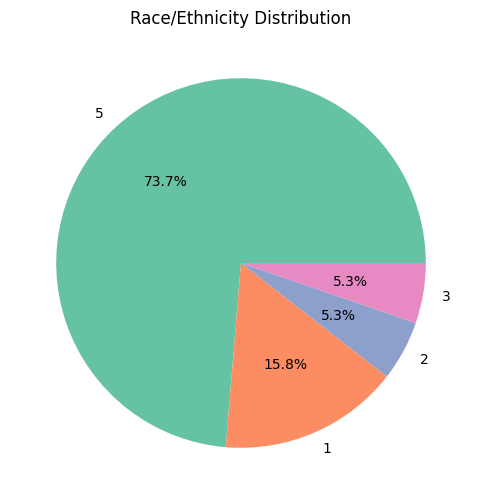

In [38]:
df = pd.read_csv(data_path / "nie_deont_responses_per_subject.csv", encoding="utf-8")

race_counts = df["Demographic.3"].value_counts()

race_counts = race_counts.drop("Race/Ethnicity")

colors = sns.color_palette("Set2", n_colors=len(race_counts))

plt.figure(figsize=(6,6))
plt.pie(race_counts.values, labels=race_counts.index, autopct="%1.1f%%", colors=colors)
plt.title("Race/Ethnicity Distribution")
plt.show()

In [39]:
# df = pd.read_csv(data_path / "nie_deont_responses_per_subject.csv", encoding="utf-8")

# politic_counts = df["Demographic.2"].value_counts()

# politic_counts = politic_counts.drop("Political View")
# order = ["Very Liberal", "Liberal", "Moderate", "Conservative", "Very Conservative", "Prefer not to say"]
# politic_counts = politic_counts.reindex(order).dropna()

# colors = sns.color_palette("Set2", n_colors=len(politic_counts))

# plt.figure(figsize=(6,6))
# plt.pie(politic_counts.values, labels=politic_counts.index, autopct="%1.1f%%", colors=colors)
# plt.title("Political View Distribution")
# plt.show()

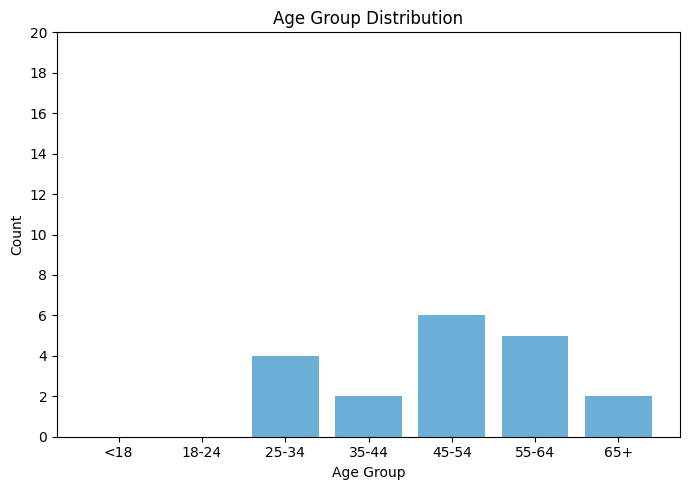

In [40]:
df = pd.read_csv(data_path / "nie_deont_responses_per_subject.csv", encoding="utf-8")

ages = df["Demographic"]

# Remove the stray header value
ages = ages[ages != "Age"]

# Convert to numeric
ages = pd.to_numeric(ages, errors="coerce").dropna()

bins = [0, 18, 25, 35, 45, 55, 65, 120]
labels = ["<18", "18-24", "25-34", "35-44", "45-54", "55-64", "65+"]

age_groups = pd.cut(ages, bins=bins, labels=labels, right=False)
age_counts = age_groups.value_counts().sort_index()

plt.figure(figsize=(7,5))
plt.bar(age_counts.index, age_counts.values, color="#6baed6")
plt.xlabel("Age Group")
plt.ylabel("Count")
plt.yticks(range(0, 21, 2))
plt.title("Age Group Distribution")
plt.tight_layout()
plt.show()

#### Building Nie Event- and Scenario-Level DataFrames (Annotator Output)

In [41]:
import nie_utility_funcs as nie_funcs

inputs_json = root_path / "scenarios_inputs" / "nie" / "nie_scenarios_NEWOPTION1.json"
outputs_dir = root_path / "annotated_outputs" / "nie"

event_df = nie_funcs.read_all_nie_scenarios(inputs_json, outputs_dir)
# read_all_nie_scenarios globs output files, so rows come out sorted by SID *as a string*
# (10 before 2) rather than numerically -- fix that with an explicit numeric sort.
event_df = event_df.sort_values("SID", kind="stable").reset_index(drop=True)
event_df.to_csv(data_path / "nie_event_level_df.csv", index=False)

print(f"number of rows: {len(event_df)}")
print(f"number of scenarios: {event_df['SID'].nunique()}")
# print(event_df.head().to_string())
display(HTML(event_df.head().to_html()))

number of rows: 287
number of scenarios: 60


,SID,option,event,C,I,K,utility,deontic,text
0,0,1,The bus with 2 passengers is struck by the train,+,-,+,"{'i': 0, '10 passengers on the bus on the main track': 95, '2 passengers on the bus on the side track': -100}",-33.0,"A high-speed train is about to hit a bus with 10 passengers. I, an employee of the train company, could redirect the train to a side track where a bus with 2 passengers is sitting."
1,0,1,The 2 passengers on the side-track bus die,+,-,+,"{'i': 0, '10 passengers on the bus on the main track': 90, '2 passengers on the bus on the side track': -100}",-33.0,"A high-speed train is about to hit a bus with 10 passengers. I, an employee of the train company, could redirect the train to a side track where a bus with 2 passengers is sitting."
2,0,1,The bus with 10 passengers is not struck by the train,+,+,+,"{'i': 0, '10 passengers on the bus on the main track': 100, '2 passengers on the bus on the side track': -90}",-33.0,"A high-speed train is about to hit a bus with 10 passengers. I, an employee of the train company, could redirect the train to a side track where a bus with 2 passengers is sitting."
3,0,1,The 10 passengers on the original bus survive,+,+,+,"{'i': 0, '10 passengers on the bus on the main track': 95, '2 passengers on the bus on the side track': 0}",-33.0,"A high-speed train is about to hit a bus with 10 passengers. I, an employee of the train company, could redirect the train to a side track where a bus with 2 passengers is sitting."
4,1,1,The bus carrying 2 passengers is pushed onto the track.,+,+,+,"{'i': 0, '10 passengers on the bus currently in the train's path': 95, '1 driver of the bus currently in the train's path': -95, '2 passengers on the bus that could be pushed onto the track': -100, '1 driver of the bus that could be pushed onto the track': -65}",-29.0,"A high-speed train is about to hit a bus with 10 passengers. I, an employee of the train company, am sitting in a truck near the intersection. I could push several cars in front of me, which would in turn push a bus with 2 passengers onto the track, thus replacing the other bus."


In [42]:
scenario_df = nie_funcs.build_scenario_level_df(event_df)
scenario_df.to_csv(data_path / "nie_scenario_level_df.csv", index=False)

print(f"number of scenarios: {len(scenario_df)}")
print(f"utility score variants: {[c for c in scenario_df.columns if c.startswith('utility_score_')]}")
# print(scenario_df.head().to_string())
display(HTML(scenario_df.head().to_html()))


number of scenarios: 60
utility score variants: ['utility_score_non_i_only_min', 'utility_score_simplest_min', 'utility_score_i_only_min']


,SID,text,deontic,utility_score_non_i_only_min,utility_score_simplest_min,utility_score_i_only_min,utility_score,pct_C_plus,pct_I_plus,pct_I_plus_harm_only
0,0,"A high-speed train is about to hit a bus with 10 passengers. I, an employee of the train company, could redirect the train to a side track where a bus with 2 passengers is sitting.",-33.0,-100.0,-100.0,0.0,-100.0,100.0,50.000000,33.333333
1,1,"A high-speed train is about to hit a bus with 10 passengers. I, an employee of the train company, am sitting in a truck near the intersection. I could push several cars in front of me, which would in turn push a bus with 2 passengers onto the track, thus replacing the other bus.",-29.0,-100.0,-100.0,-20.0,-100.0,100.0,71.428571,66.666667
2,2,"In a restaurant, a bomb threatens to kill 9 guests. The bomb could be thrown onto the patio, where 1 guest would be killed.",-80.0,-100.0,-100.0,-60.0,-100.0,100.0,50.000000,50.000000
3,3,"In a restaurant, a bomb threatens to kill 9 guests. One guest could be thrown on the bomb, which would kill this 1 guest.",-91.0,-100.0,-100.0,-65.0,-100.0,75.0,50.000000,50.000000
4,4,"A virus causing paraplegia threatens 4 patients. Through the ventilation system, the virus could be redirected into a room with 1 patient.",-54.0,-80.0,-80.0,0.0,-80.0,100.0,100.000000,100.000000
